# Import Lib

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

# Load data

In [60]:
train = pd.read_csv("../Data/train.csv")
test = pd.read_csv("../Data/test.csv")

## Checking data

In [61]:
train.shape
test.shape

(1459, 80)

In [62]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [63]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [64]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### Checking missing data

In [65]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing) 

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


### Classify missing data 

In [66]:
none_cols = [
    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'MasVnrType',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'BsmtExposure',
    'BsmtQual',
    'BsmtCond',
    'BsmtFinType1',
    'BsmtFinType2'
]

train[none_cols] = train[none_cols].fillna('None')
test[none_cols] = test[none_cols].fillna('None')

In [67]:
train['MasVnrArea'] = train['MasVnrArea'].fillna(0)
test['MasVnrArea'] = test['MasVnrArea'].fillna(0)

In [68]:
train['GarageYrBlt'] = train['GarageYrBlt'].fillna(0)
test['GarageYrBlt'] = test['GarageYrBlt'].fillna(0)

In [69]:
train['LotFrontage'] = train['LotFrontage'].fillna(train['LotFrontage'].mean())
test['LotFrontage'] = test['LotFrontage'].fillna(train['LotFrontage'].mean())

In [70]:
train['Electrical'] = train['Electrical'].fillna(
    train['Electrical'].mode()[0]
)

test['Electrical'] = test['Electrical'].fillna(
    train['Electrical'].mode()[0]
)

### Missing data after classify

In [71]:
train.isnull().sum()

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
                ..
MoSold           0
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
Length: 81, dtype: int64

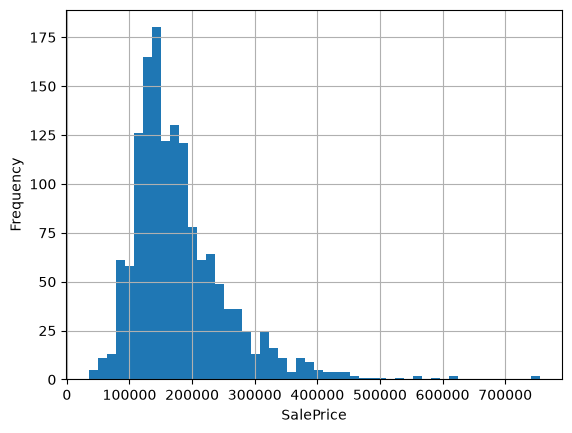

In [72]:
train['SalePrice'].hist(bins=50)
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.show()

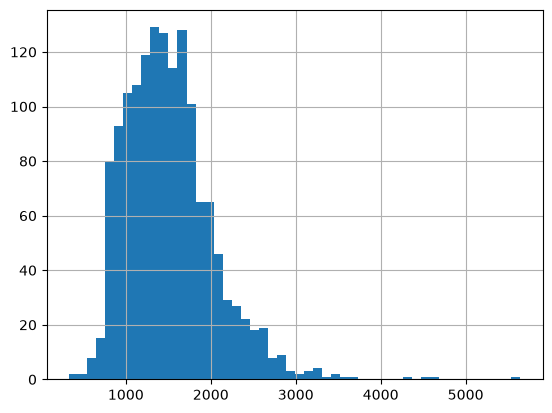

In [73]:
train['GrLivArea'].hist(bins=50)
plt.show()

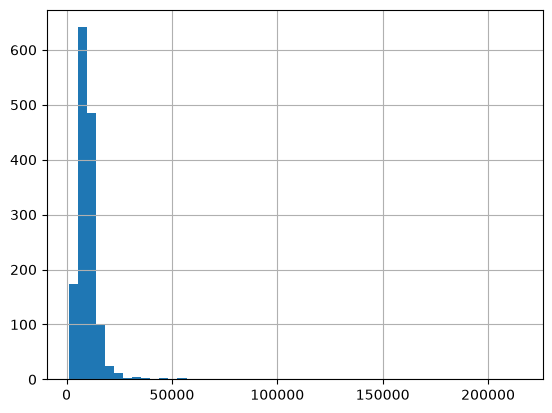

In [74]:
train['LotArea'].hist(bins=50)
plt.show()

# Features Engineering

In [75]:
train_fe = train.copy()
test_fe = test.copy()

In [76]:
train_fe['TotalSF'] = (
    train_fe['TotalBsmtSF']
    + train_fe['1stFlrSF']
    + train_fe['2ndFlrSF']
)

test_fe['TotalSF'] = (
    test_fe['TotalBsmtSF']
    + test_fe['1stFlrSF']
    + test_fe['2ndFlrSF']
)

In [77]:
train_fe['TotalSF'] =(train_fe['TotalBsmtSF'] +train_fe['1stFlrSF']+train_fe['2ndFlrSF'])
test_fe['TotalSF'] =(test_fe['TotalBsmtSF'] +test_fe['1stFlrSF']+test_fe['2ndFlrSF'])

In [78]:
train_fe[['TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'TotalSF']].head()

,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalSF
0,856,856,854,2566
1,1262,1262,0,2524
2,920,920,866,2706
3,756,961,756,2473
4,1145,1145,1053,3343


In [79]:
train_fe['HouseAge'] = train_fe['YrSold'] - train_fe['YearBuilt']

test_fe['HouseAge'] = test_fe['YrSold'] - test_fe['YearBuilt']

In [80]:
train_fe[['YearBuilt','YrSold','HouseAge']].head()

,YearBuilt,YrSold,HouseAge
0,2003,2008,5
1,1976,2007,31
2,2001,2008,7
3,1915,2006,91
4,2000,2008,8


In [81]:
train_fe['HouseAge'] = train_fe['YrSold'] - train_fe['YearBuilt']

test_fe['HouseAge'] = test_fe['YrSold'] - test_fe['YearBuilt']

In [82]:
train_fe['RemodAge'] = (
    train_fe['YrSold'] - train_fe['YearRemodAdd']
)

test_fe['RemodAge'] = (
    test_fe['YrSold'] - test_fe['YearRemodAdd']
)

In [83]:
train_fe['TotalBath'] = (
    train_fe['FullBath']
    + 0.5 * train_fe['HalfBath']
    + train_fe['BsmtFullBath']
    + 0.5 * train_fe['BsmtHalfBath']
)

test_fe['TotalBath'] = (
    test_fe['FullBath']
    + 0.5 * test_fe['HalfBath']
    + test_fe['BsmtFullBath']
    + 0.5 * test_fe['BsmtHalfBath']
)

In [84]:
train_fe['HasGarage'] = (train_fe['GarageArea'] > 0).astype(int)

test_fe['HasGarage'] = (test_fe['GarageArea'] > 0).astype(int)

In [85]:
train_fe['HasBsmt'] = (train_fe['TotalBsmtSF'] > 0).astype(int)

test_fe['HasBsmt'] = (test_fe['TotalBsmtSF'] > 0).astype(int)

In [86]:
train_fe['HasFireplace'] = (
    train_fe['Fireplaces'] > 0
).astype(int)

test_fe['HasFireplace'] = (
    test_fe['Fireplaces'] > 0
).astype(int)

In [87]:
train_fe['Has2ndFloor'] = (
    train_fe['2ndFlrSF'] > 0
).astype(int)

test_fe['Has2ndFloor'] = (
    test_fe['2ndFlrSF'] > 0
).astype(int)

In [88]:
train_fe['TotalPorchSF'] = (
    train_fe['OpenPorchSF']
    + train_fe['3SsnPorch']
    + train_fe['EnclosedPorch']
    + train_fe['ScreenPorch']
    + train_fe['WoodDeckSF']
)

In [89]:
train_fe.shape

(1460, 90)

In [90]:
train_fe[['TotalSF', 'HouseAge', 'RemodAge',
          'TotalBath', 'HasGarage', 'HasBsmt',
          'HasFireplace', 'Has2ndFloor',
          'TotalPorchSF']].head()

,TotalSF,HouseAge,RemodAge,TotalBath,HasGarage,HasBsmt,HasFireplace,Has2ndFloor,TotalPorchSF
0,2566,5,5,3.5,1,1,0,1,61
1,2524,31,31,2.5,1,1,1,0,298
2,2706,7,6,3.5,1,1,1,1,42
3,2473,91,36,2.0,1,1,1,1,307
4,3343,8,8,3.5,1,1,1,1,276


In [91]:
train_fe.isnull().sum().sort_values(ascending=False).head(20)

Id              0
MSSubClass      0
MSZoning        0
LotFrontage     0
LotArea         0
Street          0
Alley           0
LotShape        0
LandContour     0
Utilities       0
LotConfig       0
LandSlope       0
Neighborhood    0
Condition1      0
Condition2      0
BldgType        0
HouseStyle      0
OverallQual     0
OverallCond     0
YearBuilt       0
dtype: int64

In [92]:
test_fe.isnull().sum().sort_values(ascending=False).head(20)

MSZoning        4
Utilities       2
Functional      2
BsmtHalfBath    2
TotalBath       2
BsmtFullBath    2
Exterior1st     1
BsmtFinSF2      1
Exterior2nd     1
TotalBsmtSF     1
BsmtFinSF1      1
GarageCars      1
TotalSF         1
GarageArea      1
SaleType        1
KitchenQual     1
BsmtUnfSF       1
Alley           0
LotShape        0
Id              0
dtype: int64

In [93]:
corr = train_fe.select_dtypes(include=np.number).corr()

corr['SalePrice'].sort_values(ascending=False).head(15)

SalePrice       1.000000
OverallQual     0.790982
TotalSF         0.782260
GrLivArea       0.708624
GarageCars      0.640409
TotalBath       0.631731
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
MasVnrArea      0.472614
HasFireplace    0.471908
Name: SalePrice, dtype: float64

In [94]:
skewed = train_fe.select_dtypes(
    include=['int64', 'float64']
).skew().sort_values(ascending=False)

print(skewed.head(20))

MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.677616
LotFrontage       2.384950
OpenPorchSF       2.364342
SalePrice         1.882876
TotalSF           1.776700
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
TotalBsmtSF       1.524255
MSSubClass        1.407657
1stFlrSF          1.376757
dtype: float64


In [95]:
train_fe['MiscVal'] = np.log1p(train_fe['MiscVal'])
test_fe['MiscVal'] = np.log1p(test_fe['MiscVal'])

In [96]:
skewed_features = [
    'PoolArea',
    'LotArea',
    '3SsnPorch',
    'LowQualFinSF',
    'MiscVal',
    'BsmtFinSF2',
    'ScreenPorch',
    'EnclosedPorch',
    'MasVnrArea',
    'OpenPorchSF',
    'TotalSF',
    'BsmtFinSF1',
    'WoodDeckSF',
    'TotalBsmtSF',
    '1stFlrSF'
]

for col in skewed_features:
    train_fe[col] = np.log1p(train_fe[col])
    test_fe[col] = np.log1p(test_fe[col])

In [97]:
np.log1p(train_fe['KitchenAbvGr'])
np.log1p(test_fe['KitchenAbvGr'])

0       0.693147
1       0.693147
2       0.693147
3       0.693147
4       0.693147
          ...   
1454    0.693147
1455    0.693147
1456    0.693147
1457    0.693147
1458    0.693147
Name: KitchenAbvGr, Length: 1459, dtype: float64

In [98]:
train_fe['LotFrontage'] = np.log1p(train_fe['LotFrontage'])
test_fe['LotFrontage'] = np.log1p(test_fe['LotFrontage'])

In [99]:
log_features = [
    'PoolArea',
    'LotArea',
    '3SsnPorch',
    'LowQualFinSF',
    'MiscVal',
    'BsmtFinSF2',
    'ScreenPorch',
    'EnclosedPorch',
    'MasVnrArea',
    'OpenPorchSF',
    'TotalSF',
    'BsmtFinSF1',
    'WoodDeckSF',
    'TotalBsmtSF',
    '1stFlrSF',
    'LotFrontage'
]

train_fe[log_features].min().sort_values()
for col in log_features:
    train_fe[col] = np.log1p(train_fe[col])
    test_fe[col] = np.log1p(test_fe[col])

In [100]:
train_fe[log_features].skew().sort_values(ascending=False)

PoolArea         14.354604
3SsnPorch         7.646802
LowQualFinSF      7.338443
MiscVal           5.025754
ScreenPorch       3.121688
BsmtFinSF2        2.448673
EnclosedPorch     2.064763
MasVnrArea        0.420593
WoodDeckSF        0.101897
1stFlrSF         -0.047185
OpenPorchSF      -0.157072
TotalSF          -0.569342
LotArea          -0.607573
BsmtFinSF1       -0.726863
LotFrontage      -1.314000
TotalBsmtSF      -5.866042
dtype: float64

In [101]:
train_fe['TotalSF'] = (
    train_fe['TotalBsmtSF']
    + train_fe['1stFlrSF']
    + train_fe['2ndFlrSF']
)

test_fe['TotalSF'] = (
    test_fe['TotalBsmtSF']
    + test_fe['1stFlrSF']
    + test_fe['2ndFlrSF']
)

In [102]:
print(train_fe['TotalBsmtSF'].head())
print(train_fe['TotalBsmtSF'].min())
print(train_fe['TotalBsmtSF'].max())

0    2.048136
1    2.096943
2    2.057383
3    2.032004
4    2.084931
Name: TotalBsmtSF, dtype: float64
0.0
2.2739639586087383


In [103]:
skewed = train_fe.select_dtypes(include=['int64', 'float64']).skew().sort_values(ascending=False)

print(skewed.head(20))

PoolArea         14.354604
3SsnPorch         7.646802
LowQualFinSF      7.338443
MiscVal           5.025754
KitchenAbvGr      4.488397
BsmtHalfBath      4.103403
ScreenPorch       3.121688
BsmtFinSF2        2.448673
EnclosedPorch     2.064763
SalePrice         1.882876
MSSubClass        1.407657
GrLivArea         1.366560
TotalPorchSF      1.102313
BsmtUnfSF         0.920268
TotalSF           0.813206
2ndFlrSF          0.813030
OverallCond       0.693067
TotRmsAbvGrd      0.676341
HalfBath          0.675897
Fireplaces        0.649565
dtype: float64


In [104]:
log_features = [
    'MiscVal',
    'PoolArea',
    'LotArea',
    '3SsnPorch',
    'LowQualFinSF',
    'BsmtFinSF2',
    'ScreenPorch',
    'EnclosedPorch',
    'MasVnrArea',
    'LotFrontage',
    'OpenPorchSF',
    'BsmtFinSF1',
    'WoodDeckSF',
    'TotalBsmtSF',
    '1stFlrSF',
    'GrLivArea',
    'TotalSF'
]

train_fe[log_features].min().sort_values()
for col in log_features:
    train_fe[col] = np.log1p(train_fe[col])
    test_fe[col] = np.log1p(test_fe[col])

In [105]:
print(train_fe['TotalSF'].head())

0    6.755881
1    1.647482
2    6.769774
3    6.634758
4    6.964296
Name: TotalSF, dtype: float64


In [106]:
train_fe[log_features].skew().sort_values(ascending=False)

PoolArea         14.353386
3SsnPorch         7.628146
LowQualFinSF      7.315232
MiscVal           5.021131
ScreenPorch       3.116633
BsmtFinSF2        2.434962
EnclosedPorch     2.055051
MasVnrArea        0.403648
TotalSF           0.298014
WoodDeckSF        0.092076
GrLivArea        -0.006140
1stFlrSF         -0.088855
OpenPorchSF      -0.184041
LotArea          -0.738508
BsmtFinSF1       -0.752061
LotFrontage      -1.471051
TotalBsmtSF      -5.979469
dtype: float64

In [107]:
print(train_fe['TotalBsmtSF'].head(10))
print(train_fe['TotalBsmtSF'].min())
print(train_fe['TotalBsmtSF'].max())

0    1.114530
1    1.130416
2    1.117559
3    1.109224
4    1.126529
5    1.111440
6    1.141634
7    1.125166
8    1.118983
9    1.120644
Name: TotalBsmtSF, dtype: float64
0.0
1.186001470522052


In [108]:
train_fe.isnull().sum().sort_values(ascending=False)


Id              0
MSSubClass      0
MSZoning        0
LotFrontage     0
LotArea         0
               ..
HasGarage       0
HasBsmt         0
HasFireplace    0
Has2ndFloor     0
TotalPorchSF    0
Length: 90, dtype: int64

In [109]:
test_fe.isnull().sum().sort_values(ascending=False)

MSZoning        4
Utilities       2
Functional      2
BsmtHalfBath    2
TotalBath       2
               ..
RemodAge        0
HasGarage       0
HasBsmt         0
HasFireplace    0
Has2ndFloor     0
Length: 88, dtype: int64

In [110]:
cat_fill = ['MSZoning', 'Utilities', 'Functional']
num_fill = ['BsmtHalfBath', 'BsmtFullBath']

for col in cat_fill:
    test_fe[col] = test_fe[col].fillna(train_fe[col].mode()[0])

for col in num_fill:
    test_fe[col] = test_fe[col].fillna(train_fe[col].median())

In [111]:
missing_test = test_fe.isnull().sum()
missing_test = missing_test[missing_test > 0].sort_values(ascending=False)

print(missing_test)

TotalBath      2
Exterior1st    1
BsmtFinSF1     1
Exterior2nd    1
BsmtFinSF2     1
BsmtUnfSF      1
KitchenQual    1
TotalBsmtSF    1
GarageCars     1
GarageArea     1
SaleType       1
TotalSF        1
dtype: int64


In [112]:
cat_fill = [
    'Exterior1st',
    'Exterior2nd',
    'KitchenQual',
    'SaleType'
]

for col in cat_fill:
    test_fe[col] = test_fe[col].fillna(train_fe[col].mode()[0])

In [113]:
num_zero_fill = [
    'BsmtFinSF1',
    'BsmtFinSF2',
    'BsmtUnfSF',
    'TotalBsmtSF',
    'GarageCars',
    'GarageArea'
]

for col in num_zero_fill:
    test_fe[col] = test_fe[col].fillna(0)

In [114]:
test_fe['TotalSF'] = np.log1p(
    np.expm1(test_fe['TotalBsmtSF'])
    + np.expm1(test_fe['1stFlrSF'])
    + np.expm1(test_fe['2ndFlrSF'])
)

c:\Users\thanh\Desktop\Machine Learning\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in expm1
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [115]:
missing_test = test_fe.isnull().sum()
missing_test = missing_test[missing_test > 0].sort_values(ascending=False)

print(missing_test)

TotalBath    2
dtype: int64


In [116]:
print("Train NaN:", train_fe.isnull().sum().sum())
print("Test NaN :", test_fe.isnull().sum().sum())

Train NaN: 0
Test NaN : 2
